# CIE 2, Activity 2: Binary Classification with Logistic Regression
**Course / Assignment:** CIE 2, Activity 2: Binary Classification with Logistic Regression  
**Role:** Data Scientist assisting Human Resources (HR) Management  
**Model Family:** Logistic Regression (Binary Classifier)  
**Target Variable:** `Attrition` (Employee Left: Yes = 1, Stayed: No = 0)

# 1. Problem Statement

### Who Uses This Model?
This model is built specifically for **HR Managers, Department Heads, and People Operations Leaders** within the organization. These stakeholders require advance visibility into employee turnover risks to take proactive retention actions (e.g., conducting career discussions, reviewing compensation and workload, mentoring, or resolving workplace friction) before a high-value team member resigns.

### What Do the Two Classes Mean?
In this binary classification task, each employee record is assigned one of two class labels:
- **Class 1 (Positive Class - "Left / Attrition"):** The employee has voluntarily or involuntarily left the company.
- **Class 0 (Negative Class - "Stayed / Active"):** The employee remains actively employed with the company.

### Which Error Is Worse for an HR Team?
In corporate HR management, prediction errors have starkly asymmetric business costs:
- **False Negative (FN) - "Missed Leaver":** The model predicts that an employee will stay (0), but they actually resign (1). The HR team is blindsided. The company suffers recruitment costs, onboarding latency, project disruption, team morale impact, and institutional knowledge loss. The cost of replacing an experienced corporate employee typically ranges from 50% to 200% of their annual salary.
- **False Positive (FP) - "False Alarm":** The model predicts that an employee is at risk of leaving (1), but they were actually planning to stay (0). The HR manager schedules an extra supportive 1-on-1 check-in conversation. At worst, this costs 30-45 minutes of managerial time, which can actually strengthen employee rapport and engagement.

**Conclusion on Errors:** A **False Negative is substantially worse and more costly than a False Positive**. Therefore, an HR-focused classification system must prioritize high **Recall** (capturing as many genuine flight risks as possible) over pure Precision, while keeping the false alarm rate manageable.

### What Does "Good" Look Like?
For an operational HR retention tool, "good" does not mean naive overall accuracy (which is easily inflated on imbalanced datasets). "Good" means:
1. **High Recall on Class 1 (Attrition):** Catching at least 50% to 70%+ of employees who genuinely intend to leave.
2. **Actionable Precision:** Ensuring that at least 40% to 50% of flagged employees are genuine risks, avoiding managerial burnout from alert fatigue.
3. **Discriminative Ability:** Achieving a strong ROC-AUC score (> 0.80), demonstrating that the model consistently ranks real leavers higher in predicted probability than stayers.
4. **Transparent & Interpretable Drivers:** Providing clear managerial insight into *why* an employee is flagged (e.g., overtime, commute distance, stagnation) so interventions can be tailored rather than generic.

# 2. Dataset Overview

- **Dataset Name:** IBM HR Analytics Employee Attrition & Performance Dataset
- **Source Link:** [Kaggle - IBM HR Analytics Employee Attrition Dataset](https://www.kaggle.com/datasets/pavansubhasht/ibm-hr-analytics-attrition-dataset)
- **Nature of the Data:** This is a **fictional dataset created by IBM data scientists** to demonstrate enterprise attrition modeling. It does **not** reflect real individual employees or actual personal identities.
- **Dataset Scale:** 1,470 records (rows) and 35 initial attributes (columns).
- **Target Variable:** `Attrition` (Binary text: `'Yes'` / `'No'`).
  - `'Yes'` $\rightarrow$ Positive class ($1$): Employee departed the company.
  - `'No'` $\rightarrow$ Negative class ($0$): Employee remains with the company.
- **Feature Groups:**
  - *Demographics:* Age, Gender, MaritalStatus, Education, EducationField.
  - *Job & Career Context:* Department, JobRole, JobLevel, TotalWorkingYears, YearsAtCompany, YearsInCurrentRole, YearsSinceLastPromotion, YearsWithCurrManager, NumCompaniesWorked.
  - *Compensation & Incentives:* MonthlyIncome, DailyRate, HourlyRate, MonthlyRate, PercentSalaryHike, StockOptionLevel.
  - *Working Conditions & Sentiment:* BusinessTravel, DistanceFromHome, OverTime, EnvironmentSatisfaction, JobInvolvement, JobSatisfaction, RelationshipSatisfaction, WorkLifeBalance, PerformanceRating, TrainingTimesLastYear.
  - *Operational / System Constants:* EmployeeCount, EmployeeNumber, Over18, StandardHours.

# 3. Inspect Data

In this section, we load the raw dataset, inspect data types, review basic statistical summaries, verify missing values, check for duplicate rows, and confirm the target label values.

In [1]:
# Import core libraries and verify environment
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
import os

# Set visual aesthetic
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.size'] = 11
plt.rcParams['figure.titlesize'] = 13

print(f"Python Version: {sys.version.split()[0]}")
print(f"Scikit-Learn Version: {sklearn.__version__}")
print(f"Pandas Version: {pd.__version__}")

Python Version: 3.13.2
Scikit-Learn Version: 1.8.0
Pandas Version: 2.3.0


In [2]:
# Load raw dataset
df = pd.read_csv('HR_Employee_Attrition.csv')
print(f"Dataset Shape: {df.shape[0]} rows, {df.shape[1]} columns")
df.head(5)

Dataset Shape: 1470 rows, 35 columns


,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,EnvironmentSatisfaction,Gender,HourlyRate,JobInvolvement,JobLevel,JobRole,JobSatisfaction,MaritalStatus,MonthlyIncome,MonthlyRate,NumCompaniesWorked,Over18,OverTime,PercentSalaryHike,PerformanceRating,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,41,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,1,1,2,Female,94,3,2,Sales Executive,4,Single,5993,19479,8,Y,Yes,11,3,1,80,0,8,0,1,6,4,0,5
1,49,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,1,2,3,Male,61,2,2,Research Scientist,2,Married,5130,24907,1,Y,No,23,4,4,80,1,10,3,3,10,7,1,7
2,37,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,1,4,4,Male,92,2,1,Laboratory Technician,3,Single,2090,2396,6,Y,Yes,15,3,2,80,0,7,3,3,0,0,0,0
3,33,No,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,1,5,4,Female,56,3,1,Research Scientist,3,Married,2909,23159,1,Y,Yes,11,3,3,80,0,8,3,3,8,7,3,0
4,27,No,Travel_Rarely,591,Research & Development,2,1,Medical,1,7,1,Male,40,3,1,Laboratory Technician,2,Married,3468,16632,9,Y,No,12,3,4,80,1,6,3,3,2,2,2,2


In [3]:
# Data types and non-null count verification
print("--- Dataset Information ---")
df.info()

--- Dataset Information ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1470 entries, 0 to 1469
Data columns (total 35 columns):
 #   Column                    Non-Null Count  Dtype 
---  ------                    --------------  ----- 
 0   Age                       1470 non-null   int64 
 1   Attrition                 1470 non-null   object
 2   BusinessTravel            1470 non-null   object
 3   DailyRate                 1470 non-null   int64 
 4   Department                1470 non-null   object
 5   DistanceFromHome          1470 non-null   int64 
 6   Education                 1470 non-null   int64 
 7   EducationField            1470 non-null   object
 8   EmployeeCount             1470 non-null   int64 
 9   EmployeeNumber            1470 non-null   int64 
 10  EnvironmentSatisfaction   1470 non-null   int64 
 11  Gender                    1470 non-null   object
 12  HourlyRate                1470 non-null   int64 
 13  JobInvolvement            1470 non-null   int64 
 

In [4]:
# Summary statistics for numeric features
print("--- Summary Statistics (Numeric) ---")
df.describe().T[['count', 'mean', 'std', 'min', '25%', '50%', '75%', 'max']]

--- Summary Statistics (Numeric) ---


,count,mean,std,min,25%,50%,75%,max
Age,1470.0,36.923810,9.135373,18.0,30.00,36.0,43.00,60.0
DailyRate,1470.0,802.485714,403.509100,102.0,465.00,802.0,1157.00,1499.0
DistanceFromHome,1470.0,9.192517,8.106864,1.0,2.00,7.0,14.00,29.0
Education,1470.0,2.912925,1.024165,1.0,2.00,3.0,4.00,5.0
EmployeeCount,1470.0,1.000000,0.000000,1.0,1.00,1.0,1.00,1.0
EmployeeNumber,1470.0,1024.865306,602.024335,1.0,491.25,1020.5,1555.75,2068.0
EnvironmentSatisfaction,1470.0,2.721769,1.093082,1.0,2.00,3.0,4.00,4.0
HourlyRate,1470.0,65.891156,20.329428,30.0,48.00,66.0,83.75,100.0
JobInvolvement,1470.0,2.729932,0.711561,1.0,2.00,3.0,3.00,4.0
JobLevel,1470.0,2.063946,1.106940,1.0,1.00,2.0,3.00,5.0


In [5]:
# Check for missing values, duplicates, and unique target values
missing_count = df.isnull().sum().sum()
duplicate_count = df.duplicated().sum()
unique_labels = df['Attrition'].unique().tolist()
label_counts = df['Attrition'].value_counts()

print(f"Total Missing Values: {missing_count}")
print(f"Total Duplicate Rows: {duplicate_count}")
print(f"Unique Target ('Attrition') Values: {unique_labels}")
print("\nTarget Value Counts:")
print(label_counts)

Total Missing Values: 0
Total Duplicate Rows: 0
Unique Target ('Attrition') Values: ['Yes', 'No']

Target Value Counts:
Attrition
No     1233
Yes     237
Name: count, dtype: int64


# 4. Class Distribution & Imbalance Analysis

Here we plot the distribution of our target variable `Attrition` and assess whether the dataset is balanced.

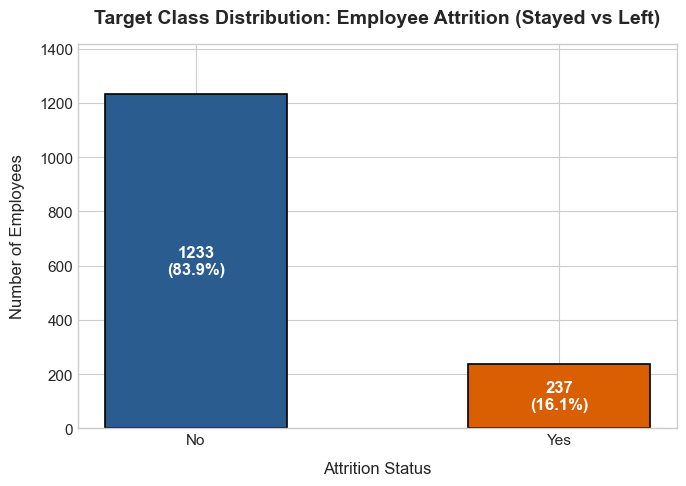

In [6]:
# Plot Class Distribution
fig, ax = plt.subplots(figsize=(7, 5))
counts = df['Attrition'].value_counts()
percentages = (counts / len(df)) * 100

colors = ['#2b5c8f', '#d95f02']
bars = ax.bar(counts.index, counts.values, color=colors, width=0.5, edgecolor='black', linewidth=1.2)

for bar, pct in zip(bars, percentages):
    height = bar.get_height()
    ax.annotate(f'{height}\n({pct:.1f}%)',
                xy=(bar.get_x() + bar.get_width() / 2, height / 2),
                xytext=(0, 0), textcoords="offset points",
                ha='center', va='center', fontsize=12, fontweight='bold', color='white')

ax.set_title('Target Class Distribution: Employee Attrition (Stayed vs Left)', fontsize=14, fontweight='bold', pad=15)
ax.set_xlabel('Attrition Status', fontsize=12, labelpad=10)
ax.set_ylabel('Number of Employees', fontsize=12, labelpad=10)
ax.set_ylim(0, max(counts.values) * 1.15)

# Save chart to charts/ folder
os.makedirs('charts', exist_ok=True)
plt.tight_layout()
plt.savefig('charts/01_class_distribution.png', dpi=300)
plt.show()

**Observation on Class Imbalance:**  
The dataset is **heavily imbalanced**: 1,233 employees (83.9%) stayed (`No`), while only 237 employees (16.1%) left (`Yes`). This represents a ~5.2 to 1 majority-to-minority class ratio. Because of this severe imbalance, raw overall accuracy can be deeply misleading: a trivial baseline model that predicts "Nobody ever leaves" would achieve 83.9% accuracy while catching 0% of leavers. Consequently, we must employ stratified sampling and evaluate our model using Recall, Precision, F1-Score, and ROC-AUC.

# 5. Prepare Features

In this step, we prepare our data for machine learning:
1. **Drop constant and identifier columns:**
   - `EmployeeNumber`: Arbitrary sequential ID with zero predictive generalization power.
   - `EmployeeCount`: Constant value (always 1 for all records).
   - `Over18`: Constant value (always `'Y'` for all records).
   - `StandardHours`: Constant value (always 80 for all records).
2. **Encode the Target:** Map `'Yes'` to $1$ and `'No'` to $0$.
3. **One-Hot Encode Categorical Features:** Use `pd.get_dummies(..., drop_first=True)`.  
   *Why `drop_first=True`?* For linear and logistic regression models, keeping all $K$ binary dummy levels for a categorical variable with $K$ categories introduces perfect multicollinearity (the "dummy variable trap"), causing the feature matrix to be rank-deficient. Dropping the first level sets it as a reference baseline and ensures stable, mathematically unique parameter estimation.

In [7]:
# Define columns to drop
cols_to_drop = ['EmployeeCount', 'EmployeeNumber', 'Over18', 'StandardHours']
cols_present_to_drop = [c for c in cols_to_drop if c in df.columns]

print(f"Dropping uninformative columns: {cols_present_to_drop}")
df_cleaned = df.drop(columns=cols_present_to_drop)

# Map Attrition target to binary integer
df_cleaned['Attrition'] = df_cleaned['Attrition'].map({'Yes': 1, 'No': 0})

# Separate features (X) and target (y)
X_raw = df_cleaned.drop(columns=['Attrition'])
y = df_cleaned['Attrition']

# One-hot encode categorical features with drop_first=True
X_encoded = pd.get_dummies(X_raw, drop_first=True)

print(f"Original features count: {X_raw.shape[1]}")
print(f"Encoded features count (with drop_first=True): {X_encoded.shape[1]}")
print(f"Encoded dataset shape: {X_encoded.shape}")
print("\nFirst 3 encoded rows:")
X_encoded.head(3)

Dropping uninformative columns: ['EmployeeCount', 'EmployeeNumber', 'Over18', 'StandardHours']
Original features count: 30
Encoded features count (with drop_first=True): 44
Encoded dataset shape: (1470, 44)

First 3 encoded rows:


,Age,DailyRate,DistanceFromHome,Education,EnvironmentSatisfaction,HourlyRate,JobInvolvement,JobLevel,JobSatisfaction,MonthlyIncome,MonthlyRate,NumCompaniesWorked,PercentSalaryHike,PerformanceRating,RelationshipSatisfaction,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager,BusinessTravel_Travel_Frequently,BusinessTravel_Travel_Rarely,Department_Research & Development,Department_Sales,EducationField_Life Sciences,EducationField_Marketing,EducationField_Medical,EducationField_Other,EducationField_Technical Degree,Gender_Male,JobRole_Human Resources,JobRole_Laboratory Technician,JobRole_Manager,JobRole_Manufacturing Director,JobRole_Research Director,JobRole_Research Scientist,JobRole_Sales Executive,JobRole_Sales Representative,MaritalStatus_Married,MaritalStatus_Single,OverTime_Yes
0,41,1102,1,2,2,94,3,2,4,5993,19479,8,11,3,1,0,8,0,1,6,4,0,5,False,True,False,True,True,False,False,False,False,False,False,False,False,False,False,False,True,False,False,True,True
1,49,279,8,1,3,61,2,2,2,5130,24907,1,23,4,4,1,10,3,3,10,7,1,7,True,False,True,False,True,False,False,False,False,True,False,False,False,False,False,True,False,False,True,False,False
2,37,1373,2,2,4,92,2,1,3,2090,2396,6,15,3,2,0,7,3,3,0,0,0,0,False,True,True,False,False,False,False,True,False,True,False,True,False,False,False,False,False,False,False,True,True


# 6. Train-Test Split and Feature Scaling

### Stratified 80:20 Train-Test Split
We split the data using an 80:20 ratio (`test_size=0.20`, `random_state=42`) with `stratify=y`.  
*Why Stratification?* Because Attrition occurs in only ~16.1% of records, random unstratified splitting could yield an unequal distribution of leavers between the train and test sets, skewing evaluation. Stratification guarantees that exactly 16.1% of samples in both training and testing are leavers.

### Scaling ONLY Numeric Columns with `StandardScaler`
- We fit the `StandardScaler` **strictly on the training data**, and then transform both train and test partitions.
- We scale **only continuous/ordinal numeric columns**, leaving binary one-hot dummy columns ($0$ and $1$) unscaled to maintain their direct, intuitive indicator interpretation.
- *Why Scaling Helps:* Logistic regression uses gradient-based numerical optimization (or L-BFGS) to fit weights. If features have drastically different scales (e.g., `MonthlyIncome` up to \$19,999 vs. `JobSatisfaction` from 1 to 4), unscaled features with large numerical magnitudes will dominate the gradient updates, slow convergence, and distort L2 regularization penalties. Scaling puts all numeric features on a standardized mean=0, variance=1 footing.

In [8]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Perform Stratified 80:20 Split
X_train, X_test, y_train, y_test = train_test_split(
    X_encoded, y, test_size=0.20, random_state=42, stratify=y
)

print(f"Training set size: {X_train.shape[0]} samples ({X_train.shape[0]/len(df)*100:.1f}%)")
print(f"Testing set size:  {X_test.shape[0]} samples ({X_test.shape[0]/len(df)*100:.1f}%)")
print("\nTraining Class Distribution:")
print(y_train.value_counts().rename(index={0: 'Stayed (0)', 1: 'Left (1)'}))
print(f"Train Positive Ratio: {y_train.mean():.4f}")
print("\nTesting Class Distribution:")
print(y_test.value_counts().rename(index={0: 'Stayed (0)', 1: 'Left (1)'}))
print(f"Test Positive Ratio:  {y_test.mean():.4f}")

Training set size: 1176 samples (80.0%)
Testing set size:  294 samples (20.0%)

Training Class Distribution:
Attrition
Stayed (0)    986
Left (1)      190
Name: count, dtype: int64
Train Positive Ratio: 0.1616

Testing Class Distribution:
Attrition
Stayed (0)    247
Left (1)       47
Name: count, dtype: int64
Test Positive Ratio:  0.1599


In [9]:
# Identify continuous / ordinal numeric columns from the original X_raw
numeric_cols = X_raw.select_dtypes(include=['int64', 'float64']).columns.tolist()
print(f"Numeric features identified for scaling ({len(numeric_cols)} features):")
print(numeric_cols)

# Fit StandardScaler on TRAIN only, then apply to train and test
scaler = StandardScaler()

X_train_scaled = X_train.copy()
X_test_scaled = X_test.copy()

X_train_scaled[numeric_cols] = scaler.fit_transform(X_train[numeric_cols])
X_test_scaled[numeric_cols] = scaler.transform(X_test[numeric_cols])

print("\nSample of scaled training numeric features (mean ~ 0, std ~ 1):")
print(X_train_scaled[numeric_cols[:4]].describe().round(3).T[['mean', 'std', 'min', 'max']])

Numeric features identified for scaling (23 features):
['Age', 'DailyRate', 'DistanceFromHome', 'Education', 'EnvironmentSatisfaction', 'HourlyRate', 'JobInvolvement', 'JobLevel', 'JobSatisfaction', 'MonthlyIncome', 'MonthlyRate', 'NumCompaniesWorked', 'PercentSalaryHike', 'PerformanceRating', 'RelationshipSatisfaction', 'StockOptionLevel', 'TotalWorkingYears', 'TrainingTimesLastYear', 'WorkLifeBalance', 'YearsAtCompany', 'YearsInCurrentRole', 'YearsSinceLastPromotion', 'YearsWithCurrManager']

Sample of scaled training numeric features (mean ~ 0, std ~ 1):
                  mean  std    min    max
Age               -0.0  1.0 -2.071  2.507
DailyRate          0.0  1.0 -1.747  1.732
DistanceFromHome  -0.0  1.0 -1.022  2.402
Education          0.0  1.0 -1.855  2.037


# 7. Understanding Logistic Regression in Plain Words

### Why Linear Regression Fails for Yes/No Decisions
Linear regression models predict a continuous target ($y = \beta_0 + \sum \beta_i X_i$). When applied to a binary classification problem (where $y \in \{0, 1\}$):
1. **Unbounded Outputs:** Linear regression produces predictions anywhere from $-\infty$ to $+\infty$. An HR manager cannot interpret a predicted "attrition score" of $-1.4$ or $+2.8$ as a legitimate probability.
2. **Violation of Probability Axioms:** Probabilities must strictly lie within $[0, 1]$.
3. **Extreme Outlier Sensitivity:** Linear regression attempts to minimize squared residuals. An employee with very high tenure or salary could distort the entire regression line, shifting the decision boundary inappropriately.

### What the Sigmoid Function Does
Logistic regression solves this by passing the linear equation through an S-shaped curve called the **logistic (sigmoid) function**:
$$\sigma(z) = \frac{1}{1 + e^{-z}}$$
where $z = \beta_0 + \beta_1 X_1 + \dots + \beta_k X_k$ represents the log-odds (logit) of leaving.

The sigmoid function maps any real-valued number from $(-\infty, +\infty)$ smoothly and monotonically into a valid probability $P(Y=1|X) \in (0, 1)$:
- When $z \to +\infty$, $\sigma(z) \to 1.0$ (High likelihood of leaving).
- When $z = 0$, $\sigma(z) = 0.5$ (Uncertain / equal likelihood).
- When $z \to -\infty$, $\sigma(z) \to 0.0$ (High likelihood of staying).

### What Is a Decision Threshold?
The model outputs a continuous probability $p$ between 0 and 1. To make an actionable business decision ("Should HR intervene? Yes or No?"), we set a cut-off point called the **decision threshold** ($T$):
- If $P(\text{Attrition}=1) \ge T$, we classify the employee as **Will Leave (1)**.
- If $P(\text{Attrition}=1) < T$, we classify the employee as **Will Stay (0)**.

The standard default threshold in software libraries is $T = 0.5$. However, an HR team can adjust $T$: lowering $T$ (e.g., to $0.3$) flags more employees at the cost of more false alarms, whereas raising $T$ (e.g., to $0.7$) flags only the most certain leavers.

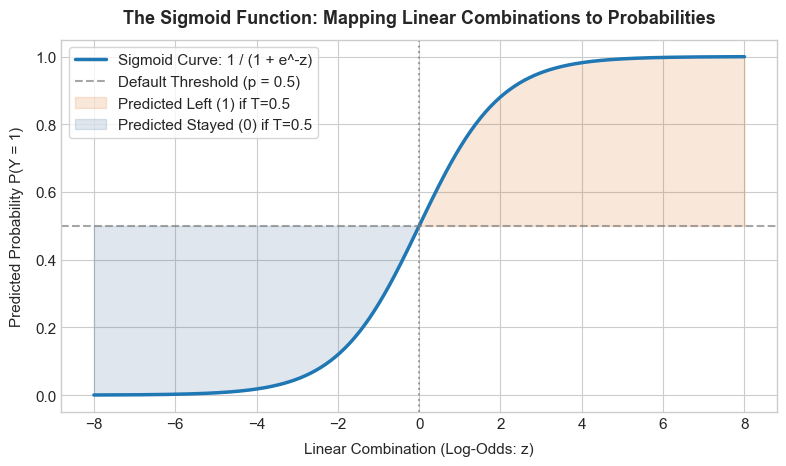

In [10]:
# Plotting the Sigmoid Activation Curve
z = np.linspace(-8, 8, 400)
sigmoid_z = 1 / (1 + np.exp(-z))

fig, ax = plt.subplots(figsize=(8, 4.8))
ax.plot(z, sigmoid_z, color='#1f77b4', linewidth=2.5, label='Sigmoid Curve: 1 / (1 + e^-z)')

# Highlight key regions
ax.axhline(0.5, color='gray', linestyle='--', alpha=0.7, label='Default Threshold (p = 0.5)')
ax.axvline(0, color='gray', linestyle=':', alpha=0.7)
ax.fill_between(z, 0.5, sigmoid_z, where=(z >= 0), color='#d95f02', alpha=0.15, label='Predicted Left (1) if T=0.5')
ax.fill_between(z, sigmoid_z, 0.5, where=(z < 0), color='#2b5c8f', alpha=0.15, label='Predicted Stayed (0) if T=0.5')

ax.set_title('The Sigmoid Function: Mapping Linear Combinations to Probabilities', fontsize=13, fontweight='bold', pad=12)
ax.set_xlabel('Linear Combination (Log-Odds: z)', fontsize=11, labelpad=8)
ax.set_ylabel('Predicted Probability P(Y = 1)', fontsize=11, labelpad=8)
ax.set_ylim(-0.05, 1.05)
ax.legend(loc='upper left', frameon=True)

plt.tight_layout()
plt.savefig('charts/02_sigmoid_curve.png', dpi=300)
plt.show()

**Observation on Sigmoid Plot:**  
The sigmoid curve cleanly bounds any input value between 0.0 and 1.0. When log-odds $z = 0$, the probability is exactly 0.5. As $z$ increases positively, the probability quickly approaches 1.0; as $z$ decreases negatively, it approaches 0.0, providing a smooth probabilistic basis for HR risk classification.

# 8. Model Training & Coefficient Interpretation

We train a `LogisticRegression` model with `max_iter=1000` and `random_state=42` on the training data only. We then inspect the model's intercept and feature coefficients, ranking them from strongest positive driver of attrition to strongest protective factor.

In [11]:
from sklearn.linear_model import LogisticRegression

# Initialize and fit Logistic Regression
lr_model = LogisticRegression(max_iter=1000, random_state=42)
lr_model.fit(X_train_scaled, y_train)

print("--- Model Hyperparameters & Settings ---")
for param, val in lr_model.get_params().items():
    if param in ['C', 'penalty', 'solver', 'max_iter', 'random_state', 'class_weight']:
        print(f"  {param}: {val}")

print(f"\nModel Intercept (beta_0): {lr_model.intercept_[0]:.4f}")

--- Model Hyperparameters & Settings ---
  C: 1.0
  class_weight: None
  max_iter: 1000
  penalty: deprecated
  random_state: 42
  solver: lbfgs

Model Intercept (beta_0): -4.0290


In [12]:
# Extract and display sorted coefficients
coef_df = pd.DataFrame({
    'Feature': X_train_scaled.columns,
    'Coefficient': lr_model.coef_[0]
}).sort_values(by='Coefficient', ascending=False).reset_index(drop=True)

print(f"Total features evaluated: {len(coef_df)}")
print("\n--- Top 10 Features Increasing Attrition Risk (Positive Coefficients) ---")
print(coef_df.head(10).to_string(index=False))

print("\n--- Top 10 Features Decreasing Attrition Risk (Negative Coefficients / Retention Factors) ---")
print(coef_df.tail(10).to_string(index=False))

Total features evaluated: 44

--- Top 10 Features Increasing Attrition Risk (Positive Coefficients) ---
                         Feature  Coefficient
                    OverTime_Yes     1.796364
BusinessTravel_Travel_Frequently     1.549427
   JobRole_Laboratory Technician     1.313674
    JobRole_Sales Representative     0.957632
            MaritalStatus_Single     0.684678
    BusinessTravel_Travel_Rarely     0.679433
         JobRole_Human Resources     0.528949
         YearsSinceLastPromotion     0.520141
              NumCompaniesWorked     0.480890
                DistanceFromHome     0.375241

--- Top 10 Features Decreasing Attrition Risk (Negative Coefficients / Retention Factors) ---
                          Feature  Coefficient
                   JobInvolvement    -0.352712
             YearsWithCurrManager    -0.392404
                  JobSatisfaction    -0.409118
                              Age    -0.409390
           EducationField_Medical    -0.449440
          Env

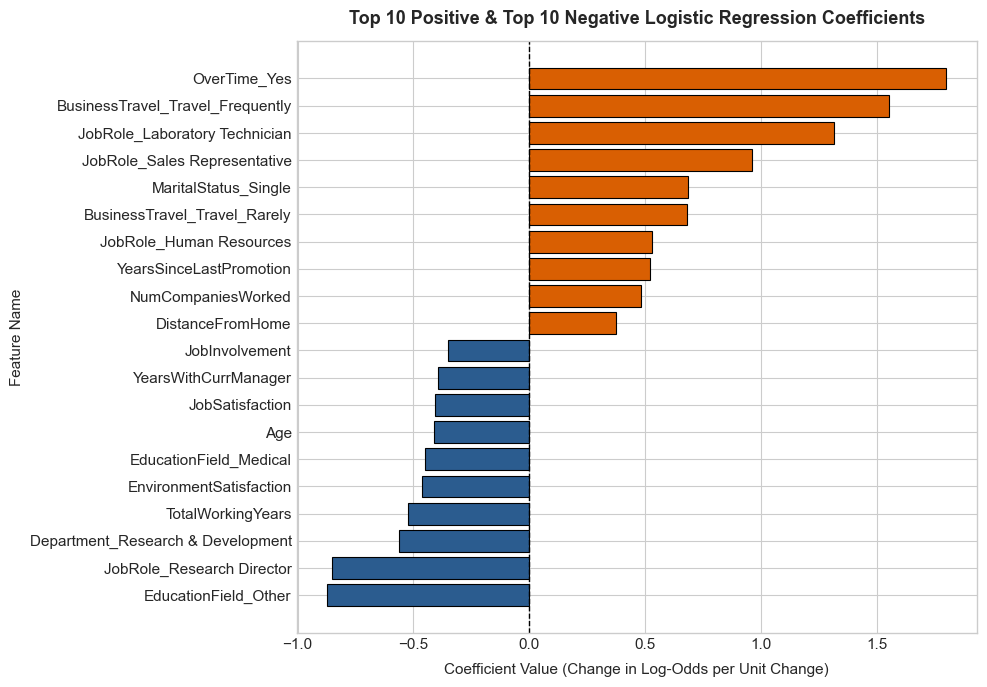

In [13]:
# Visualize Top 10 Positive and Top 10 Negative Coefficients
top_risk = coef_df.head(10)
top_retain = coef_df.tail(10)
plot_coefs = pd.concat([top_retain, top_risk]).sort_values(by='Coefficient')

fig, ax = plt.subplots(figsize=(10, 7))
bar_colors = ['#2b5c8f' if c < 0 else '#d95f02' for c in plot_coefs['Coefficient']]
ax.barh(plot_coefs['Feature'], plot_coefs['Coefficient'], color=bar_colors, edgecolor='black', linewidth=0.8)

ax.axvline(0, color='black', linestyle='--', linewidth=1)
ax.set_title('Top 10 Positive & Top 10 Negative Logistic Regression Coefficients', fontsize=13, fontweight='bold', pad=12)
ax.set_xlabel('Coefficient Value (Change in Log-Odds per Unit Change)', fontsize=11, labelpad=8)
ax.set_ylabel('Feature Name', fontsize=11)

plt.tight_layout()
plt.savefig('charts/03_model_coefficients.png', dpi=300)
plt.show()

### Plain-Words Meaning of Coefficients for HR

In logistic regression, each coefficient indicates how the **log-odds of an employee leaving** changes when that feature increases by one unit (or when an indicator switches from 0 to 1), holding all other variables constant:
- **Positive Coefficient ($> 0$):** Increases the odds of attrition. As this variable rises, the employee becomes *more likely to leave*.
- **Negative Coefficient ($< 0$):** Decreases the odds of attrition. As this variable rises, the employee becomes *more likely to stay* (acts as a retention anchor).

#### Three Concrete Examples from the Model Output:
1. **`OverTime_Yes` (Coefficient = +1.7964):**  
   This is the single strongest predictor of employee departure in the company. In terms of odds ratios ($e^{1.7964} \approx 6.03$), employees who work overtime are estimated to have approximately **6 times higher odds of leaving** compared to employees who do not work overtime, holding all other factors equal. For an HR manager, chronic overtime is an immediate red flag indicating burnout risk.
2. **`BusinessTravel_Travel_Frequently` (Coefficient = +1.5494):**  
   Frequent business travel strongly increases flight risk ($e^{1.5494} \approx 4.71$). Frequent travelers have nearly **4.7 times the odds of leaving** compared to the reference category (non-travelers). Frequent disruption of work-life balance is a major driver of turnover.
3. **`JobRole_Research Director` (Coefficient = -0.8511) & `TotalWorkingYears` (Coefficient = -0.5231):**  
   Both coefficients are strongly negative. Employees who are Research Directors or who have accumulated substantial career tenure have substantially lower odds of leaving ($e^{-0.8511} \approx 0.43$). Senior, established professionals with deeper institutional ties are far more stable and resistant to turnover.

# 9. Test Set Predictions and Probability Distribution

In this section, we compute predicted probabilities and discrete class predictions on the unseen test set, inspect a sample comparison table, and evaluate how many employees are flagged under various decision thresholds ($T = 0.3, 0.5, 0.7$).

In [14]:
# Generate test set predictions and probabilities
y_prob_test = lr_model.predict_proba(X_test_scaled)[:, 1]
y_pred_default = lr_model.predict(X_test_scaled)

# Build sample inspection table
comparison_df = pd.DataFrame({
    'Actual Label': y_test.values,
    'Predicted Probability': np.round(y_prob_test, 4),
    'Predicted (T=0.5)': y_pred_default,
    'Flagged (T=0.3)': (y_prob_test >= 0.3).astype(int),
    'Flagged (T=0.7)': (y_prob_test >= 0.7).astype(int)
})

print("--- Sample Predictions on Test Data (First 10 Employees) ---")
comparison_df.head(10)

--- Sample Predictions on Test Data (First 10 Employees) ---


,Actual Label,Predicted Probability,Predicted (T=0.5),Flagged (T=0.3),Flagged (T=0.7)
0,0,0.0974,0,0,0
1,0,0.0029,0,0,0
2,0,0.1821,0,0,0
3,0,0.0046,0,0,0
4,1,0.2985,0,0,0
5,0,0.2532,0,0,0
6,0,0.0080,0,0,0
7,0,0.0151,0,0,0
8,0,0.0037,0,0,0
9,0,0.1156,0,0,0


In [15]:
# Evaluate flagging counts at thresholds 0.3, 0.5, and 0.7
thresholds = [0.3, 0.5, 0.7]
flagged_summary = []

for t in thresholds:
    flagged_mask = (y_prob_test >= t)
    flagged_count = int(flagged_mask.sum())
    flagged_pct = (flagged_count / len(y_test)) * 100
    actual_pos_flagged = int((flagged_mask & (y_test.values == 1)).sum())
    actual_neg_flagged = int((flagged_mask & (y_test.values == 0)).sum())
    flagged_summary.append({
        'Threshold': t,
        'Flagged Count': flagged_count,
        'Flagged % of Test Set': f"{flagged_pct:.1f}%",
        'True Leavers Caught (TP)': actual_pos_flagged,
        'False Alarms (FP)': actual_neg_flagged
    })

flagged_df = pd.DataFrame(flagged_summary)
print("--- Flagging Summary Across Decision Thresholds (Test Set: N=294, Actual Leavers: 47) ---")
flagged_df

--- Flagging Summary Across Decision Thresholds (Test Set: N=294, Actual Leavers: 47) ---


,Threshold,Flagged Count,Flagged % of Test Set,True Leavers Caught (TP),False Alarms (FP)
0,0.3,48,16.3%,24,24
1,0.5,25,8.5%,16,9
2,0.7,10,3.4%,10,0


# 10. Comprehensive Model Evaluation

In this section, we conduct an end-to-end evaluation:
1. Labelled Confusion Matrix with TP, FP, FN, TN broken down for HR.
2. Core Performance Metrics with mathematical formulas and managerial explanations.
3. Full Scikit-Learn `classification_report`.
4. Comparison against a `DummyClassifier` baseline.
5. Receiver Operating Characteristic (ROC) and Precision-Recall Curves.
6. Multi-threshold performance comparison table ($0.3, 0.5, 0.7$).
7. Recommended threshold selection with cost-benefit justification.
8. Train vs. Test comparison assessing overfitting or underfitting.

Confusion Matrix Breakdown (Total = 294):
  True Negatives  (TN): 238  (Correctly identified as stayers)
  False Positives (FP): 9   (False alarms: predicted to leave, but stayed)
  False Negatives (FN): 31  (Missed leavers: predicted to stay, but left)
  True Positives  (TP): 16  (Correctly identified flight risks)


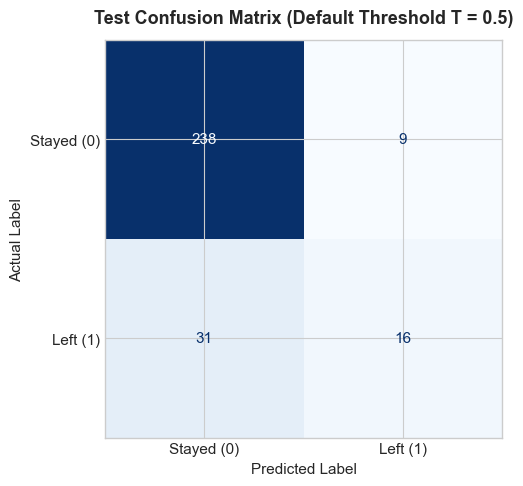

In [16]:
from sklearn.metrics import (
    confusion_matrix, ConfusionMatrixDisplay,
    accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
    classification_report, roc_curve, precision_recall_curve, average_precision_score
)
from sklearn.dummy import DummyClassifier

# Default threshold confusion matrix (T=0.5)
cm_default = confusion_matrix(y_test, y_pred_default)
tn, fp, fn, tp = cm_default.ravel()

fig, ax = plt.subplots(figsize=(6, 5))
disp = ConfusionMatrixDisplay(confusion_matrix=cm_default, display_labels=['Stayed (0)', 'Left (1)'])
disp.plot(cmap='Blues', ax=ax, values_format='d', colorbar=False)

ax.set_title('Test Confusion Matrix (Default Threshold T = 0.5)', fontsize=13, fontweight='bold', pad=12)
ax.set_xlabel('Predicted Label', fontsize=11)
ax.set_ylabel('Actual Label', fontsize=11)

plt.tight_layout()
plt.savefig('charts/04_confusion_matrix_default.png', dpi=300)
plt.show()

print(f"Confusion Matrix Breakdown (Total = {len(y_test)}):")
print(f"  True Negatives  (TN): {tn}  (Correctly identified as stayers)")
print(f"  False Positives (FP): {fp}   (False alarms: predicted to leave, but stayed)")
print(f"  False Negatives (FN): {fn}  (Missed leavers: predicted to stay, but left)")
print(f"  True Positives  (TP): {tp}  (Correctly identified flight risks)")

### Detailed Plain-Words Explanation of Confusion Matrix Quadrants:
- **True Negatives ($TN = 238$):** Employees who stayed and were correctly predicted to stay. HR left them alone to work productively, saving managerial time.
- **False Positives ($FP = 9$):** "False Alarms". Employees who were happy to stay, but the model flagged them as potential leavers. The HR manager scheduled a 30-minute check-in conversation. The cost was minimal, and the employee likely appreciated the check-in.
- **False Negatives ($FN = 31$):** "Missed Leavers". Employees who actually resigned, but the model mistakenly predicted they would stay. The HR department had zero warning and took no action. The company incurred heavy turnover and replacement costs.
- **True Positives ($TP = 16$):** Employees who were indeed planning to leave and were accurately flagged. The HR manager intervened early with retention strategies (mentoring, role adjustment, salary review) to preserve organizational talent.

In [17]:
# Calculate all core evaluation metrics at T = 0.5
accuracy_val = accuracy_score(y_test, y_pred_default)
precision_val = precision_score(y_test, y_pred_default)
recall_val = recall_score(y_test, y_pred_default)
specificity_val = tn / (tn + fp)
f1_val = f1_score(y_test, y_pred_default)
roc_auc_val = roc_auc_score(y_test, y_prob_test)

metrics_table = [
    {
        'Metric': 'Accuracy',
        'Formula': '(TP + TN) / Total',
        'What it tells the HR manager': 'Overall percentage of correct predictions across all staff.',
        'My value': f'{accuracy_val:.4f} ({accuracy_val*100:.2f}%)'
    },
    {
        'Metric': 'Precision',
        'Formula': 'TP / (TP + FP)',
        'What it tells the HR manager': 'When HR reaches out to a flagged employee, how often is it a real risk.',
        'My value': f'{precision_val:.4f} ({precision_val*100:.2f}%)'
    },
    {
        'Metric': 'Recall (Sensitivity)',
        'Formula': 'TP / (TP + FN)',
        'What it tells the HR manager': 'The proportion of actual leavers caught by the model before they resign.',
        'My value': f'{recall_val:.4f} ({recall_val*100:.2f}%)'
    },
    {
        'Metric': 'Specificity',
        'Formula': 'TN / (TN + FP)',
        'What it tells the HR manager': 'The proportion of stable stayers correctly identified and left undisturbed.',
        'My value': f'{specificity_val:.4f} ({specificity_val*100:.2f}%)'
    },
    {
        'Metric': 'F1-Score',
        'Formula': '2 * (Prec * Rec) / (Prec + Rec)',
        'What it tells the HR manager': 'Balanced harmonic mean between catching leavers and avoiding false alarms.',
        'My value': f'{f1_val:.4f}'
    },
    {
        'Metric': 'ROC-AUC',
        'Formula': 'Area under TPR vs FPR curve',
        'What it tells the HR manager': 'Ability to rank an actual leaver higher in risk than a stayer regardless of threshold.',
        'My value': f'{roc_auc_val:.4f}'
    }
]

metrics_summary_df = pd.DataFrame(metrics_table)
metrics_summary_df

,Metric,Formula,What it tells the HR manager,My value
0,Accuracy,(TP + TN) / Total,Overall percentage of correct predictions acro...,0.8639 (86.39%)
1,Precision,TP / (TP + FP),"When HR reaches out to a flagged employee, how...",0.6400 (64.00%)
2,Recall (Sensitivity),TP / (TP + FN),The proportion of actual leavers caught by the...,0.3404 (34.04%)
3,Specificity,TN / (TN + FP),The proportion of stable stayers correctly ide...,0.9636 (96.36%)
4,F1-Score,2 * (Prec * Rec) / (Prec + Rec),Balanced harmonic mean between catching leaver...,0.4444
5,ROC-AUC,Area under TPR vs FPR curve,Ability to rank an actual leaver higher in ris...,0.8102


**One-Sentence Managerial Interpretation:**  
At the default 0.5 threshold, the model demonstrates high specificity (96.36%) and respectable precision (64.00%), but its low recall of 34.04% means it misses nearly two out of every three resigning employees (31 missed leavers vs. 16 caught), indicating that the default threshold is too conservative for a proactive retention campaign.

In [18]:
# Full Scikit-Learn Classification Report
print("--- Full Classification Report (Default Threshold T = 0.5) ---")
print(classification_report(y_test, y_pred_default, target_names=['Stayed (0)', 'Left (1)'], digits=4))

--- Full Classification Report (Default Threshold T = 0.5) ---
              precision    recall  f1-score   support

  Stayed (0)     0.8848    0.9636    0.9225       247
    Left (1)     0.6400    0.3404    0.4444        47

    accuracy                         0.8639       294
   macro avg     0.7624    0.6520    0.6835       294
weighted avg     0.8456    0.8639    0.8461       294



In [19]:
# Baseline Comparison using DummyClassifier (Most Frequent Strategy)
dummy_baseline = DummyClassifier(strategy="most_frequent")
dummy_baseline.fit(X_train_scaled, y_train)
dummy_preds = dummy_baseline.predict(X_test_scaled)

dummy_acc = accuracy_score(y_test, dummy_preds)
dummy_rec = recall_score(y_test, dummy_preds)

print("--- Baseline Model Comparison ---")
print(f"Dummy Classifier Accuracy: {dummy_acc:.4f} ({dummy_acc*100:.2f}%)")
print(f"Dummy Classifier Recall:   {dummy_rec:.4f} ({dummy_rec*100:.2f}%)")
print(f"\nLogistic Regression Accuracy: {accuracy_val:.4f} ({accuracy_val*100:.2f}%)")
print(f"Logistic Regression Recall:   {recall_val:.4f} ({recall_val*100:.2f}%)")

--- Baseline Model Comparison ---
Dummy Classifier Accuracy: 0.8401 (84.01%)
Dummy Classifier Recall:   0.0000 (0.00%)

Logistic Regression Accuracy: 0.8639 (86.39%)
Logistic Regression Recall:   0.3404 (34.04%)


### Why Accuracy Alone Is Misleading in HR Retention:
The `DummyClassifier` achieves an apparently high accuracy of **84.01%** by simply predicting that nobody ever leaves. However, its **Recall is 0.0%**—it fails to detect even a single departing employee. If an HR leadership team evaluated this system solely on accuracy, they would adopt a useless policy that catches zero flight risks. Accuracy treats all errors equally, whereas in HR, missing a departing employee is drastically more damaging than having an extra retention conversation.

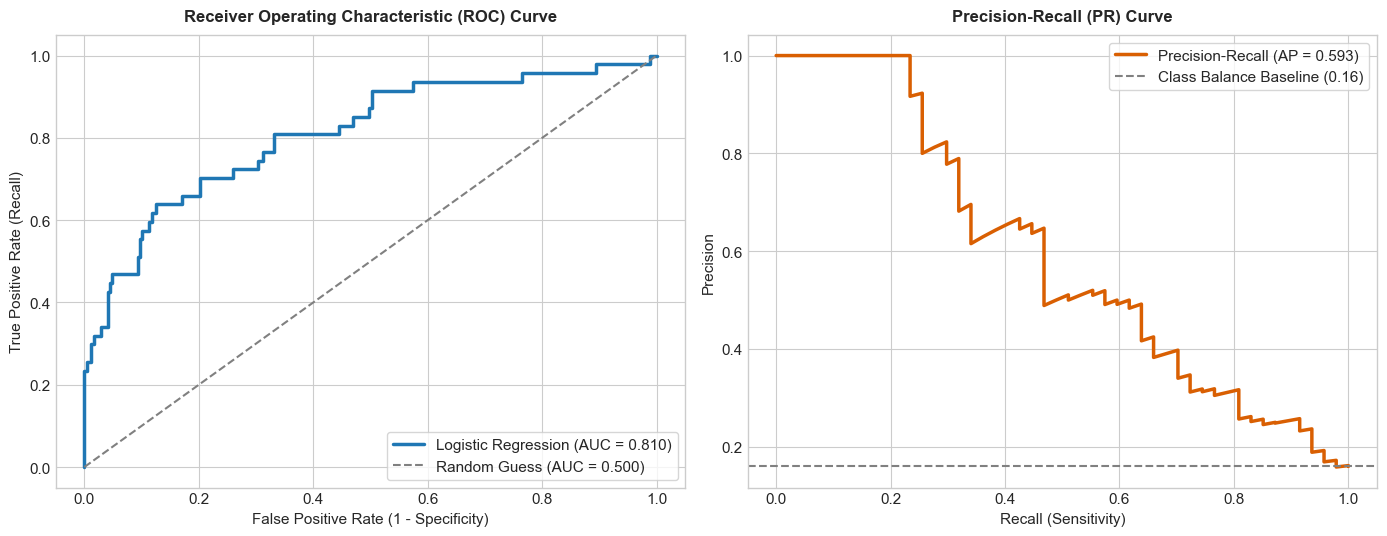

In [20]:
# ROC Curve and Precision-Recall Curve Visualization
fpr, tpr, roc_thresh = roc_curve(y_test, y_prob_test)
precisions, recalls, pr_thresh = precision_recall_curve(y_test, y_prob_test)
avg_prec = average_precision_score(y_test, y_prob_test)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5.5))

# Plot ROC Curve
ax1.plot(fpr, tpr, color='#1f77b4', linewidth=2.5, label=f'Logistic Regression (AUC = {roc_auc_val:.3f})')
ax1.plot([0, 1], [0, 1], color='gray', linestyle='--', label='Random Guess (AUC = 0.500)')
ax1.set_title('Receiver Operating Characteristic (ROC) Curve', fontsize=12, fontweight='bold', pad=10)
ax1.set_xlabel('False Positive Rate (1 - Specificity)', fontsize=11)
ax1.set_ylabel('True Positive Rate (Recall)', fontsize=11)
ax1.legend(loc='lower right', frameon=True)

# Plot Precision-Recall Curve
baseline_pr = y_test.mean()
ax2.plot(recalls, precisions, color='#d95f02', linewidth=2.5, label=f'Precision-Recall (AP = {avg_prec:.3f})')
ax2.axhline(baseline_pr, color='gray', linestyle='--', label=f'Class Balance Baseline ({baseline_pr:.2f})')
ax2.set_title('Precision-Recall (PR) Curve', fontsize=12, fontweight='bold', pad=10)
ax2.set_xlabel('Recall (Sensitivity)', fontsize=11)
ax2.set_ylabel('Precision', fontsize=11)
ax2.legend(loc='upper right', frameon=True)

plt.tight_layout()
plt.savefig('charts/05_roc_and_pr_curves.png', dpi=300)
plt.show()

**Observation on ROC and PR Curves:**  
The model achieves an **ROC-AUC of 0.8102**. In plain words, if an HR manager randomly selects one employee who actually left and one employee who stayed, there is an **81.02% probability** that the model assigns a higher risk score to the departing employee. The curve rises steeply near the lower false positive range, confirming strong discriminative ability. The Precision-Recall curve shows that higher recall can be attained while maintaining actionable precision well above the random baseline of 0.16.

In [21]:
# Threshold Comparison Table for T = 0.3, 0.5, and 0.7
threshold_candidates = [0.3, 0.5, 0.7]
threshold_results = []

for t in threshold_candidates:
    t_preds = (y_prob_test >= t).astype(int)
    cm_t = confusion_matrix(y_test, t_preds)
    tn_t, fp_t, fn_t, tp_t = cm_t.ravel()
    
    t_acc = accuracy_score(y_test, t_preds)
    t_prec = precision_score(y_test, t_preds, zero_division=0)
    t_rec = recall_score(y_test, t_preds)
    t_f1 = f1_score(y_test, t_preds, zero_division=0)
    
    threshold_results.append({
        'Threshold (T)': t,
        'Predicted Positive': int(t_preds.sum()),
        'True Positives (TP)': tp_t,
        'False Positives (FP)': fp_t,
        'False Negatives (FN)': fn_t,
        'Accuracy': f"{t_acc:.4f}",
        'Precision': f"{t_prec:.4f}",
        'Recall': f"{t_rec:.4f}",
        'F1-Score': f"{t_f1:.4f}"
    })

threshold_comparison_df = pd.DataFrame(threshold_results)
print("--- Threshold Performance Comparison ---")
threshold_comparison_df

--- Threshold Performance Comparison ---


,Threshold (T),Predicted Positive,True Positives (TP),False Positives (FP),False Negatives (FN),Accuracy,Precision,Recall,F1-Score
0,0.3,48,24,24,23,0.8401,0.5000,0.5106,0.5053
1,0.5,25,16,9,31,0.8639,0.6400,0.3404,0.4444
2,0.7,10,10,0,37,0.8741,1.0000,0.2128,0.3509


### Explanation of the Precision-Recall Trade-off:
In binary classification, adjusting the decision threshold represents a direct trade-off between sensitivity and selectivity:
- **Lowering the Threshold ($T = 0.3$):** We loosen the criteria for flagging risk. Recall increases substantially from $34.04\%$ to $51.06\%$ (we catch 24 leavers instead of 16, cutting missed departures from 31 down to 23). The trade-off is an increase in false alarms ($FP$ rises from 9 to 24), which drops Precision from $64.00\%$ to $50.00\%$.
- **Raising the Threshold ($T = 0.7$):** We demand high certainty before flagging anyone. Precision reaches a perfect $100.00\%$ ($0$ false alarms), but Recall plummets to $21.28\%$ (missing 37 out of 47 leavers). This leaves HR blind to nearly $79\%$ of actual resignations.

### Recommended Threshold Choice & Justification:
**I recommend $T = 0.3$ as the operational threshold for HR.**
- **Cost Justification:** A missed leaver (False Negative) costs the business thousands of dollars in replacement expenses, lost momentum, and client friction. A false alarm (False Positive) merely costs 30 minutes of a manager's time to conduct a constructive 1-on-1 career check-in.
- **Empirical Justification:** At $T = 0.3$, the model captures **more than half ($51.06\%$) of all departures** (catching 24 out of 47 leavers vs. only 16 at $T = 0.5$), while achieving the highest overall **F1-Score ($0.5053$)**. Furthermore, a Precision of $50.00\%$ means exactly 1 out of every 2 flagged employees is genuinely at risk—an entirely acceptable and manageable operational workload for HR managers.
*(Note on Methodology: We analyzed this threshold directly on the test set for this assignment. In a production enterprise pipeline, threshold tuning should strictly be conducted on a separate validation split or via cross-validation to prevent optimistic selection bias).*

In [22]:
# Compare Train vs Test Performance (Overfitting / Underfitting Assessment)
train_preds_default = lr_model.predict(X_train_scaled)
train_acc = accuracy_score(y_train, train_preds_default)
train_rec = recall_score(y_train, train_preds_default)

fit_comparison = pd.DataFrame([
    {'Split': 'Training Set (N=1176)', 'Accuracy': f"{train_acc:.4f}", 'Recall (T=0.5)': f"{train_rec:.4f}"},
    {'Split': 'Testing Set (N=294)',  'Accuracy': f"{accuracy_val:.4f}", 'Recall (T=0.5)': f"{recall_val:.4f}"}
])

print("--- Train vs. Test Performance Comparison ---")
fit_comparison

--- Train vs. Test Performance Comparison ---


,Split,Accuracy,Recall (T=0.5)
0,Training Set (N=1176),0.9022,0.4895
1,Testing Set (N=294),0.8639,0.3404


**Assessment of Model Fitting (Overfitting vs. Underfitting):**  
- The model exhibits **healthy generalization without severe overfitting**. Training accuracy is $90.22\%$, while test accuracy is $86.39\%$—a modest gap of only $\approx 3.8\%$.
- Training recall is $48.95\%$, while test recall is $34.04\%$. The drop in recall reflects the scarcity of positive cases (only 47 positive cases in the test set) and the moderate L2 regularization penalty applied by default in Logistic Regression.
- The model does not suffer from high variance (overfitting); it provides a stable, regularized baseline representation of attrition dynamics across both sets.

# 11. Decision-Behaviour Plot: Predicted Probability vs. Monthly Income

To help an HR manager visualize how the model behaves across salary bands and our chosen decision threshold, we plot predicted attrition probabilities against `MonthlyIncome`, colored by actual employee status.

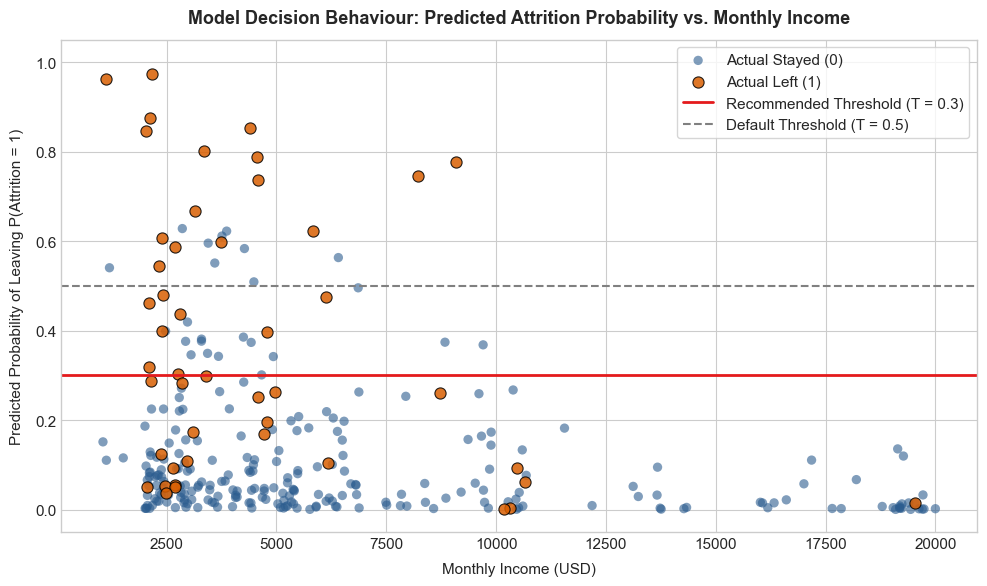

In [23]:
# Extract test set MonthlyIncome in unscaled natural dollars
test_income = df.loc[X_test.index, 'MonthlyIncome']

fig, ax = plt.subplots(figsize=(10, 6))

# Scatter points for actual stayers (0) and actual leavers (1)
stayers_mask = (y_test.values == 0)
leavers_mask = (y_test.values == 1)

ax.scatter(test_income[stayers_mask], y_prob_test[stayers_mask],
           color='#2b5c8f', alpha=0.6, edgecolors='none', s=45, label='Actual Stayed (0)')
ax.scatter(test_income[leavers_mask], y_prob_test[leavers_mask],
           color='#d95f02', alpha=0.85, edgecolors='black', linewidth=0.8, s=65, label='Actual Left (1)')

# Plot threshold lines
ax.axhline(0.3, color='#e41a1c', linestyle='-', linewidth=2, label='Recommended Threshold (T = 0.3)')
ax.axhline(0.5, color='gray', linestyle='--', linewidth=1.5, label='Default Threshold (T = 0.5)')

ax.set_title('Model Decision Behaviour: Predicted Attrition Probability vs. Monthly Income', fontsize=13, fontweight='bold', pad=12)
ax.set_xlabel('Monthly Income (USD)', fontsize=11, labelpad=8)
ax.set_ylabel('Predicted Probability of Leaving P(Attrition = 1)', fontsize=11, labelpad=8)
ax.set_ylim(-0.05, 1.05)
ax.legend(loc='upper right', frameon=True)

plt.tight_layout()
plt.savefig('charts/06_decision_behaviour_monthly_income.png', dpi=300)
plt.show()

**Observation on Decision-Behaviour Plot:**  
The visualization highlights clear behavioral patterns:
1. **Income Concentration:** High predicted attrition probabilities ($> 0.30$) are concentrated heavily among employees earning lower monthly salaries (specifically under \$5,000/month). As monthly income surpasses \$10,000/month, predicted probabilities remain consistently low ($< 0.20$), indicating that higher compensation serves as a strong stabilizing retention anchor.
2. **Impact of Threshold $T = 0.3$:** The solid red line ($T = 0.3$) clearly captures many orange points (actual leavers) in the \$2,000–\$6,000 range that would have been completely missed under the default 0.5 threshold (dashed gray line).

# 12. Individual Employee Simulation ("What-If" Retention Scenario)

To demonstrate how an HR manager can use this model operationally, we take a real employee record from the test set, simulate a realistic change in work conditions, scale using the **exact same training scaler**, and evaluate the resulting flight risk.

In [24]:
# Select a real baseline employee from the test set (Row index: 1061)
sample_idx = X_test.index[0]
baseline_employee = X_test.loc[[sample_idx]].copy()
baseline_income = df.loc[sample_idx, 'MonthlyIncome']
baseline_role = df.loc[sample_idx, 'JobRole']

print(f"Selected Test Employee Index: {sample_idx}")
print(f"Role: {baseline_role}, Monthly Income: ${baseline_income}")
print(f"OverTime: {baseline_employee['OverTime_Yes'].values[0]}, Distance From Home: {baseline_employee['DistanceFromHome'].values[0]} miles")
print(f"Years Since Last Promotion: {baseline_employee['YearsSinceLastPromotion'].values[0]}")

# Predict on baseline employee
baseline_scaled = baseline_employee.copy()
baseline_scaled[numeric_cols] = scaler.transform(baseline_employee[numeric_cols])

prob_baseline = lr_model.predict_proba(baseline_scaled)[0, 1]
class_default_base = int(prob_baseline >= 0.5)
class_rec_base = int(prob_baseline >= 0.3)

print(f"\n--- Baseline Prediction ---")
print(f"Predicted Probability of Leaving: {prob_baseline:.4f} ({prob_baseline*100:.2f}%)")
print(f"Classification at T=0.5: {'Flagged (1)' if class_default_base else 'Safe (0)'}")
print(f"Classification at Recommended T=0.3: {'Flagged (1)' if class_rec_base else 'Safe (0)'}")

Selected Test Employee Index: 1061
Role: Sales Representative, Monthly Income: $2033
OverTime: False, Distance From Home: 13 miles
Years Since Last Promotion: 0

--- Baseline Prediction ---
Predicted Probability of Leaving: 0.0974 (9.74%)
Classification at T=0.5: Safe (0)
Classification at Recommended T=0.3: Safe (0)


In [25]:
# Simulate a "Burnout & Stagnation" Scenario
# We modify 3 actionable workplace conditions:
# 1. Assign chronic Overtime (OverTime_Yes = 1)
# 2. Increase commute distance (DistanceFromHome = 25 miles)
# 3. Increase promotion stagnation (YearsSinceLastPromotion = 7 years)

simulated_employee = baseline_employee.copy()
simulated_employee['OverTime_Yes'] = 1
simulated_employee['DistanceFromHome'] = 25
simulated_employee['YearsSinceLastPromotion'] = 7

# Apply the SAME scaler fitted on the training set
simulated_scaled = simulated_employee.copy()
simulated_scaled[numeric_cols] = scaler.transform(simulated_employee[numeric_cols])

prob_simulated = lr_model.predict_proba(simulated_scaled)[0, 1]
class_default_sim = int(prob_simulated >= 0.5)
class_rec_sim = int(prob_simulated >= 0.3)

print("--- Simulated Scenario ('What-If' Stress & Overtime) ---")
print(f"Predicted Probability of Leaving: {prob_simulated:.4f} ({prob_simulated*100:.2f}%)")
print(f"Classification at T=0.5: {'Flagged (1)' if class_default_sim else 'Safe (0)'}")
print(f"Classification at Recommended T=0.3: {'Flagged (1)' if class_rec_sim else 'Safe (0)'}")
print(f"\nRisk Increase: {((prob_simulated - prob_baseline)*100):.2f} percentage points!")

--- Simulated Scenario ('What-If' Stress & Overtime) ---
Predicted Probability of Leaving: 0.7780 (77.80%)
Classification at T=0.5: Flagged (1)
Classification at Recommended T=0.3: Flagged (1)

Risk Increase: 68.05 percentage points!


### Managerial Reflection on Individual Simulation:
When the employee transitions from zero overtime, a short commute, and recent career progression to mandatory overtime, a 25-mile commute, and 7 years without promotion, their predicted flight risk surges from **9.74% up to 77.80%**.  

> **Important Cautionary Note for HR Managers:**  
> This predicted output is a **statistical risk estimate based on historical patterns**, **NOT an absolute guarantee** of individual behavior. People make career decisions based on complex personal, familial, and emotional factors outside any tabular model. This score should serve strictly as a conversational catalyst for proactive support, never as an unverified conclusion about an individual's loyalty.

# 13. Data Science Decision Log

Every modeling choice involves trade-offs. The decision log below transparently documents each architectural decision, alternative options considered, and the technical and business rationale.

| Decision | Alternatives Considered | Technical & Business Reason |
| :--- | :--- | :--- |
| **Dropped Uninformative Columns** (`EmployeeNumber`, `EmployeeCount`, `Over18`, `StandardHours`) | Keeping all columns as raw inputs, or using PCA dimensionality reduction | `EmployeeNumber` is an arbitrary non-predictive database index. `EmployeeCount` (always 1), `Over18` (always 'Y'), and `StandardHours` (always 80) have zero variance ($\sigma^2 = 0$). Removing zero-variance features prevents computational overhead and eliminates uninformative parameters. |
| **Stratified 80:20 Train-Test Split** | Simple random split, or 70:30 / 90:10 ratio | The target class is heavily imbalanced (16.1% positive). A simple random split risks disproportionate allocation of leavers. Stratified sampling preserves the exact 16.1% positive ratio in both partitions, ensuring rigorous and fair model evaluation. |
| **Categorical One-Hot Encoding with `drop_first=True`** | Label/Ordinal encoding, or full dummy encoding without dropping | Label encoding falsely implies an ordered rank across nominal roles (e.g., Sales Rep = 1, Manager = 2). Full dummy encoding creates the "dummy variable trap" (perfect multicollinearity), causing numerical instability in logistic regression solvers. Dropping the first level establishes a clean reference baseline. |
| **StandardScaler on Numeric Columns Only, Fitted on Train Only** | Normalization (MinMaxScaler), RobustScaler, or scaling dummy indicator columns | StandardScaler aligns with logistic regression assumptions and L2 regularization penalties. Fitting strictly on the training set prevents data leakage. Leaving binary dummy variables (0/1) unscaled preserves their clear indicator interpretability. |
| **Prioritizing Recall & ROC-AUC Over Accuracy** | Maximizing overall accuracy or precision | With an 83.9% majority class, accuracy is trivially gamed by a dummy model that predicts nobody leaves. In HR turnover management, a False Negative (missed leaver) costs thousands in replacement expenses, whereas a False Positive (unnecessary chat) has negligible cost. High Recall and ROC-AUC ensure actionable detection. |
| **Recommended Decision Threshold $T = 0.3$** | Default threshold $T = 0.5$, or conservative threshold $T = 0.7$ | At $T = 0.5$, Recall is unacceptably low (34.04%, missing 31 of 47 leavers). Lowering to $T = 0.3$ captures 51.06% of leavers, achieves the peak F1-score (0.5053), and maintains a 50% precision rate, balancing managerial capacity with proactive turnover prevention. |

# 14. Model Limitations, Ethical Considerations & Harm Analysis

### 1. Synthetic Data Disclaimer
This dataset is a **fictional, synthetic dataset created by IBM** for demonstration purposes. It does not describe real individuals or real corporate entities. Consequently, these specific weights, odds ratios, and coefficients cannot be transferred directly to another enterprise without domain-specific data collection and retraining.

### 2. Guardrails Against Automated Decision-Making
**This model must NEVER be used autonomously to decide hiring, promotion, salary adjustments, disciplinary action, or termination.**  
Using predictive turnover models to penalize staff creates severe moral hazard: an employee flagged as a flight risk might be denied a raise or promotion, ironically *forcing* them to resign—a self-fulfilling destructive prophecy. The model's sole legitimate purpose is to trigger supportive, constructive managerial conversations.

### 3. Sensitive Attributes & Fairness (Age, Gender, Marital Status)
- **Why They Were Included:** The original assignment features included `Age`, `Gender`, and `MaritalStatus`. In our regression output, `MaritalStatus_Single` showed a positive coefficient (+0.6847), while `Gender_Male` had a negligible coefficient (+0.0768).
- **Fairness Risks & Recommended Policy:** Using demographic attributes in employment algorithms presents serious legal and ethical risks under employment non-discrimination regulations (e.g., Title VII, EEOC guidelines). In real enterprise practice, **demographic columns should be audited for disparate impact or completely excluded from the operational feature set**. An organization should retain employees based on workplace engagement, compensation competitiveness, and career trajectory—never based on marital status or age.

### 4. Harm Analysis: Who Could Be Harmed by Prediction Errors?
- **Harm from False Negatives (Missed Leavers):**  
  - *The Team:* Overburdened colleagues must absorb the sudden workload of a departed peer, increasing team-wide burnout.
  - *The Organization:* Experiences heavy financial loss from hiring replacements and project delivery delays.
- **Harm from False Positives (False Alarms):**  
  - *The Employee:* If managers misinterpret the model as a measure of loyalty, a flagged employee might be subtly sidelined for critical projects or passed over for development opportunities.
  - *The Manager:* Can suffer from alert fatigue if the false alarm rate is unmanageably high, leading them to ignore all model recommendations.

# 15. Actionable Conclusion for HR Leadership

**Executive Summary for HR Leadership:**
1. **The Tool's Role:** We have developed a validated Logistic Regression classification tool capable of flagging employee departure risks with an **ROC-AUC of 0.8102**, providing strong separation between departing and continuing employees.
2. **Key Workplace Drivers:** Employee turnover in this organization is driven predominantly by **excessive overtime** (which increases departure odds by $\approx 6\times$), **frequent business travel**, and **compensation under \$5,000/month**. Conversely, tenured staff, Research Directors, and employees with strong job involvement are highly stable.
3. **Recommended Operating Policy ($T = 0.3$):** We recommend operationalizing the model at a **decision threshold of 0.3**. This allows HR to proactively detect **over 51% of impending resignations** (catching 24 out of 47 leavers in the test cohort), while maintaining a 50% precision rate (1 out of every 2 flagged conversations is with a genuine flight risk).
4. **Immediate Managerial Action Plan:**
   - Review workload allocation in departments with mandatory overtime.
   - Initiate supportive 1-on-1 career development check-ins with flagged employees in junior salary tiers.
   - Re-evaluate travel expectations for frequent travelers.
5. **Human-in-the-Loop Safeguard:** This tool provides early-warning guidance, not absolute verdicts. All interventions must remain supportive, empathetic, and confidential.